<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">Cenário 3 - SRM</h1>
</div>

# Contextualização do Experimento
Neste cenário, analisamos um teste A/B cujo objetivo é avaliar se a alteração de um botão na página inicial produz um aumento na taxa de cliques (CTR).

Para isso, comparamos duas versões:

- **Grupo de controle (A):** utiliza o botão original, com o texto "Garantir um teste gratuito".
- **Grupo experimental (B):** utiliza o botão modificado, com o texto "Inscreva-se agora".

## Hipóteses estatísticas
Para avaliar o efeito da alteração, estabelecemos as seguintes hipóteses:
- **Hipótese Nula (H₀):** não existe diferença entre as taxas de cliques dos grupos de controle e experimental.
- **Hipótese Alternativa (H₁):** existe diferença entre as taxas de cliques dos grupos de controle e experimental.

Os parâmetros estatísticos utilizados neste experimento seguem o planejamento experimental documentado no README do projeto.

## Descrição do Dataset
O conjunto de dados contém os registros de exposição dos usuários às duas variantes do experimento e a indicação de ocorrência ou não de um clique.

Cada linha representa um registro de usuário no experimento, contendo as seguintes variáveis:

| Variável | Descrição |
|---|---|
| `user_id` | Identificador único do usuário. |
| `click` | Indica se ocorreu um clique: 1 para sim e 0 para não. |
| `group` | Identifica a variante à qual o usuário foi atribuído: `con` (controle) ou `exp` (experimental). |
| `timestamp` | Data e horário do registro de exposição do usuário. |

**Observação:** a variável `click` será utilizada para calcular a taxa de cliques de cada grupo, enquanto `group` permitirá separar os resultados entre as variantes experimentais.

## Análise Exploratória e Validação dos Dados
Antes de realizar o teste estatístico, vamos examinar o conjunto de dados para compreender sua estrutura e verificar sua consistência. Nesta etapa, serão avaliados:
- Dimensões do dataset e tipos das variáveis.
- Existência de valores ausentes e registros duplicados.
- Distribuição dos usuários entre os grupos.
- Quantidade de cliques e não cliques em cada variante.
- Taxas de cliques observadas em cada grupo.

Após essa validação, os dados estarão preparados para a aplicação dos testes estatísticos e interpretação dos resultados.

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">1 Importando Bibliotecas e Dataset</h1>
</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import norm, chisquare

import sys
import os

sys.path.append(os.path.abspath(".."))
import utils.analysis_utils as func

#Configuração do matplotlib
plt.style.use('default')

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("../data-raw/user-data-cenario3-srm.csv", parse_dates=["timestamp"])
display(df)

,user_id,click,group,timestamp
0,1,1,exp,2024-01-01 00:00:54
1,2,0,con,2024-01-01 00:01:09
2,3,0,exp,2024-01-01 00:01:50
3,4,0,con,2024-01-01 00:02:03
4,5,0,con,2024-01-01 00:02:16
...,...,...,...,...
19995,19996,1,con,2024-01-14 23:53:31
19996,19997,0,con,2024-01-14 23:55:00
19997,19998,0,con,2024-01-14 23:58:19
19998,19999,0,con,2024-01-14 23:58:39


## 1.1 Checagens Básicas de Qualidade

Antes de qualquer teste: tipos, nulos, duplicados e valores esperados.

In [3]:
func.df_summary_report(df)

,Coluna,Tipo,Quantidade de Dados Não Vazios,Quantidade de Dados Vazios,Valores Únicos,Valor mais Frequente,Frequência,Porcentagem de Unicidade,Porcentagem de Valor Vazios (%),Consumo de Memória - Total: 1.45 (MB)
0,user_id,int64,20000,0,20000,1,1,100.00,0.00,0.152588
1,click,int64,20000,0,2,0.000000,15788,0.01,0.00,0.152588
2,group,str,20000,0,2,con,11000,0.01,0.00,0.991821
3,timestamp,datetime64[us],20000,0,19840,2024-01-01 00:12:24,2,99.20,0.00,0.152588


In [4]:
df.describe()

,user_id,click,timestamp
count,20000.000000,20000.000000,20000
mean,10000.500000,0.210600,2024-01-08 00:09:31.539850
min,1.000000,0.000000,2024-01-01 00:00:54
25%,5000.750000,0.000000,2024-01-04 11:47:23
50%,10000.500000,0.000000,2024-01-08 00:55:30
75%,15000.250000,0.000000,2024-01-11 11:51:49.500000
max,20000.000000,1.000000,2024-01-14 23:59:56
std,5773.647028,0.407745,NaN


## 1.2 Sample Ratio Mismatch (SRM)

A primeira etapa é verificar a Incompatibilidade da Proporção da Amostra, serve como alarme para detectar se o teste está corrompido devido a falhas técnicas ou vieses na distribuição dos usuários. 

Planejamos dividir 50/50. Se a divisão observada for muito diferente do planejado, algo está errado na atribuição e **os resultados não são confiáveis**, mesmo que o teste Z dê "significativo".

Usamos um teste **qui-quadrado**: 
- H₀ = a divisão real é 50/50. 

Um p-valor **muito baixo** (convenção comum: < 0,001) indica SRM.

In [5]:
contagem = df["group"].value_counts().reindex(["con","exp"])
print(contagem)

esperado = [len(df)/2]*2
p_srm = chisquare(contagem.values, esperado).pvalue
print(f"\np-valor do teste de SRM: {p_srm:.2e}")

if p_srm < 0.001:
    print("⚠️ Possível SRM: investigar a atribuição antes de continuar.")
else:
    print("✅ Sem sinal de SRM: a divisão está compatível com 50/50.")

group
con    11000
exp     9000
Name: count, dtype: int64

p-valor do teste de SRM: 2.09e-45
⚠️ Possível SRM: investigar a atribuição antes de continuar.


Foi detectado SRM (divisão 55/45 contra 50/50 planejado, p < 0,001). Isso indica um problema na atribuição ou na coleta e compromete a validade da comparação. Não recomendamos tomar decisão com base nestes dados. Próximos passos: investigar a causa, corrigi-la e reexecutar o experimento.

## 1.3 Visão Geral por Grupo

In [6]:
resumo = df.groupby("group")["click"].agg(Usuários = "count", Cliques = "sum", CTR = "mean").loc[["con", "exp"]]
resumo["CTR"] = resumo["CTR"].round(4)
resumo

,Usuários,Cliques,CTR
group,,,
con,11000,2199,0.1999
exp,9000,2013,0.2237


## 1.4 Contagem de cliques


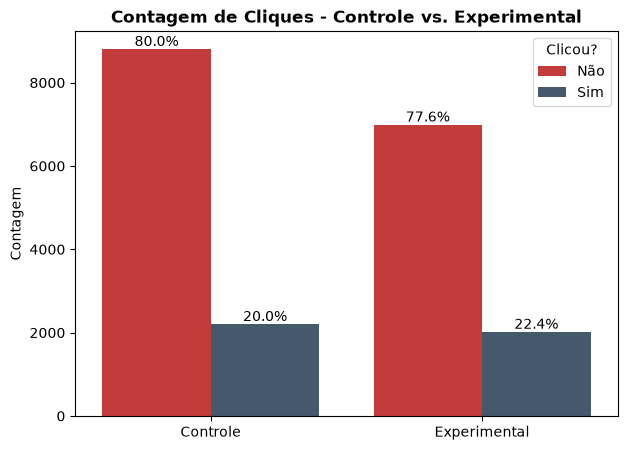

In [7]:
func.plot_click(df)

## 1.5 Parâmetros

Agora irei analisar os parâmetros Alpha, Poder e Delta, eles são essenciais no estudo estatístico de um Teste A/B para definir o tamanho da amostra necessária e garantir que os resultados sejam confiáveis.

In [8]:
alpha = 0.05
power = 0.80
delta = 0.02   # absoluto: 0,02 = 2 pontos percentuais

print(f"α = {alpha} | poder = {power} | δ = {delta} ({delta*100:.0f} p.p.)")

α = 0.05 | poder = 0.8 | δ = 0.02 (2 p.p.)


<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">2 Planejamento - Tamanho de Amostra</h1>
</div>

Definir o tamanho da amostra é de extrema importância em um Teste A/B, ela é o resultado matemático dos três parâmetros, Alpha, Poder e Delta, Eles funcionam como uma balança de precisão:

- **Para reduzir o Alpha (falsos-positivos):** Se você quer ter muita certeza de que o vencedor não foi obra do acaso, você precisa de um filtro mais rigoroso. Filtros rigorosos exigem **mais dados (amostra maior)**.
- **Para aumentar o Poder (evitar falsos-negativos):** Se você quer que o teste seja altamente sensível para não deixar passar nenhuma oportunidade, você precisa coletar **mais dados (amostra maior)**.
- **Para detectar um Delta menor (Mínimo Efeito Detectável):** Pense no Delta como o tamanho de um objeto que você está procurando no fundo do mar. Se o objeto é gigante (um Delta grande, ex: aumentar conversão em 50%), você precisa de pouca luz (pouca amostra) para ver. Se o objeto é minúsculo (um Delta pequeno, ex: aumento sutil de 1%), você precisa de um holofote gigante. Esse holofote é uma **amostra massiva**. 

Vamos responder a seguinte pergunta:
> **Quantos usuários **por grupo** precisamos para detectar uma diferença de δ = 2 p.p. com α = 0,05 e poder de 80%?**

Fórmula para duas proporções (teste bilateral):

$$n = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \,[\,p_1(1-p_1) + p_2(1-p_2)\,]}{\delta^2}, \quad p_2 = p_1 + \delta$$

O `p₁` (CTR base) normalmente vem de dados históricos. Aqui usamos o CTR observado no controle como aproximação.

In [9]:
p1 = resumo.loc["con", "CTR"]
p2 = p1 + delta

z_alpha = norm.ppf(1 - alpha / 2)
z_beta = norm.ppf(power)

num_necessario = ((z_alpha + z_beta) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2))) / delta ** 2
num_necessario = int(np.ceil(num_necessario))

print(f"CTR base (controle): {p1:.4f}  →  CTR alvo: {p2:.4f}")
print(f"Usuários necessários por grupo: {num_necessario}")
print(f"Usuários que temos por grupo:   {contagem['con']} (con) / {contagem['exp']} (exp)")

if contagem.min() >= num_necessario:
    print("✅ A amostra é suficiente para detectar δ com o poder desejado.")
else:
    print("⚠️ Amostra menor que o necessário: o teste pode não detectar um efeito de tamanho δ.")

CTR base (controle): 0.1999  →  CTR alvo: 0.2199
Usuários necessários por grupo: 6505
Usuários que temos por grupo:   11000 (con) / 9000 (exp)
✅ A amostra é suficiente para detectar δ com o poder desejado.


“A amostra de cada grupo (9.000 a 11.000) supera o mínimo de 6.505 necessário para detectar δ = 2 p.p. com 80% de poder. No entanto, isso não resolve o SRM identificado o tamanho da amostra afeta a precisão da estimativa, mas não corrige um viés na atribuição dos grupos.”

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">3 Diagnóstico</h1>
</div>

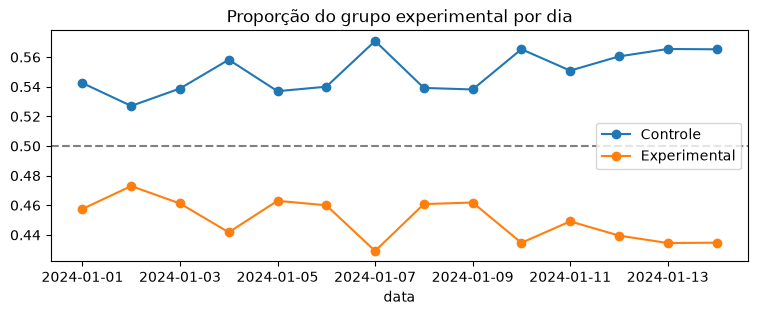

In [ ]:
df["data"] = df["timestamp"].dt.date
diario = df.groupby(["data", "group"]).size().unstack()

total = diario["con"] + diario["exp"]

diario["prop_exp"] = diario["exp"] / total
diario["prop_con"] = diario["con"] / total

#ax = diario["prop_exp"].plot(marker="o", figsize=(8, 3))
ax = diario[["prop_con", "prop_exp"]].plot(marker="o",figsize=(9, 3))
ax.axhline(0.5, color="gray", ls="--")
ax.set_title("Proporção de usuários de cada grupo por dia”.")
ax.legend(["Controle", "Experimental"])

plt.show()

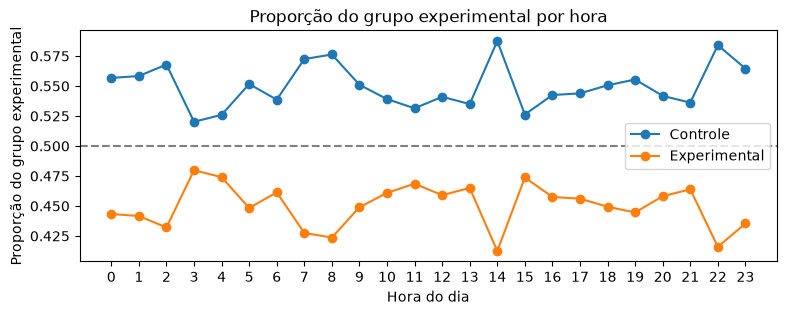

In [ ]:
df["hora"] = df["timestamp"].dt.hour

horario = df.groupby(["hora", "group"]).size().unstack(fill_value=0)

total = (horario["con"] + horario["exp"])

horario["prop_exp"] = (horario["exp"] / total)
horario["prop_con"] = (horario["con"] / total)

ax = horario[["prop_con", "prop_exp"]].plot(marker="o",figsize=(9, 3))

ax.axhline(0.5, color="gray", ls="--")
ax.set_xticks(range(24))
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Proporção do grupo experimental")
ax.set_title("Proporção de usuários de cada grupo por hora.")
ax.legend(["Controle", "Experimental"])
plt.show()


A proporção de usuários em cada grupo permaneceu fora de 50% em todos os dias do experimento (controle ~54–57%, experimental ~43–47%), indicando um desvio persistente e não um evento isolado.

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">4 Teste Z de Duas Proporções</h1>
</div>

## 4.1 Estatísticas por Grupo

O Teste Z de Duas Proporções é um método estatístico utilizado para **verificar se existe uma diferença estatisticamente significativa entre as proporções de dois grupos independentes.** No contexto de um Teste A/B, ele é especialmente útil para avaliar se uma alteração realizada em uma página, botão, formulário ou anúncio provocou uma mudança em uma determinada taxa, como:
- Taxa de cliques (CTR);
- Taxa de conversão;
- Taxa de inscrições;
- Taxa de abertura de e-mails;
- Taxa de conclusão de cadastros.

Convenção de sinal do projeto: **diferença = experimental − controle**.
Assim, valores positivos significam que o botão novo ganhou.

In [25]:
resumo = df.groupby("group")["click"].agg(["count", "sum"])

n_con, x_con = resumo.loc["con", "count"], resumo.loc["con", "sum"]
n_exp, x_exp = resumo.loc["exp", "count"], resumo.loc["exp", "sum"]

ctr_con = x_con / n_con
ctr_exp = x_exp / n_exp

diff = ctr_exp - ctr_con                 # diferença absoluta (exp − con)
lift = diff / ctr_con                    # ganho relativo

print(f"Controle:      {x_con} cliques / {n_con} usuários  → CTR = {ctr_con:.4f}")
print(f"Experimental:  {x_exp} cliques / {n_exp} usuários  → CTR = {ctr_exp:.4f}")
print(f"\nDiferença absoluta (exp − con): {diff:.4f}  ({diff*100:.2f} p.p.)")
print(f"Lift relativo:                  {lift:.2%}")

Controle:      2199 cliques / 11000 usuários  → CTR = 0.1999
Experimental:  2013 cliques / 9000 usuários  → CTR = 0.2237

Diferença absoluta (exp − con): 0.0238  (2.38 p.p.)
Lift relativo:                  11.88%


## 4.2 Estatística Z e P-Valor

Sob H₀ os dois grupos têm o **mesmo** p, então a melhor estimativa dele junta os dois grupos (proporção **combinada**):

$$\hat{p}_{comb} = \frac{X_{con} + X_{exp}}{n_{con} + n_{exp}}; \qquad EP_{comb} = \sqrt{\hat{p}_{comb}(1-\hat{p}_{comb})\left(\tfrac{1}{n_{con}} + \tfrac{1}{n_{exp}}\right)}; \qquad Z = \frac{\hat{p}_{exp} - \hat{p}_{con}}{EP_{comb}}$$

In [26]:
# Cálculo da proporção combinada (p_comb)
p_comb = (x_con + x_exp) / (n_con + n_exp)

# Cálculo do erro padrão combinado (EP_comb)
ep_comb = np.sqrt(p_comb * (1 - p_comb) * (1 / n_con + 1 / n_exp))

# Cálculo estatística Z (Z_stat)
z_stat = diff / ep_comb

# Cálculo do valor crítico (Z_critico)
z_critico = norm.ppf(1 - alpha / 2)  

# Cálculo do P-valor
p_valor = 2 * norm.sf(abs(z_stat))

print("---"*30)
print(f"Proporção combinada:     {p_comb:.5f}")
print(f"Erro padrão combinado:   {ep_comb:.5f}")
print(f"Estatística Z:           {z_stat:.2f}")
print(f"Valor crítico (±):       {z_critico:.2f}")
print(f"P-valor:                 {p_valor:.5f}")
print("---"*30)

print("--- Resultado Estatístico ---")
if p_valor <= alpha:
    print(f"✅ Rejeitamos H0 (p ≤ α = {alpha}): a diferença é estatisticamente significativa.")
else:
    print(f"❌ Não rejeitamos H0 (p > α = {alpha}): sem evidência suficiente de diferença.")

------------------------------------------------------------------------------------------
Proporção combinada:     0.21060
Erro padrão combinado:   0.00580
Estatística Z:           4.10
Valor crítico (±):       1.96
P-valor:                 0.00004
------------------------------------------------------------------------------------------
--- Resultado Estatístico ---
✅ Rejeitamos H0 (p ≤ α = 0.05): a diferença é estatisticamente significativa.


O teste Z, executado de forma exploratória, mostra diferença significativa (Z = 4,10; p < 0,001), mas esse resultado não pode ser usado para decidir, pois o SRM compromete a premissa de aleatorização. O teste Z não detecta esse tipo de problema: o p-valor seria igualmente ‘convincente’ com ou sem viés na atribuição.

As etapas de IC e significância prática foram omitidas, pois o SRM compromete a validade da comparação e esses resultados não sustentariam uma decisão.

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">Conclusão</h1>
</div>